# Predicting race outcomes in Formula 1, 2014–2021: revised analysis

This notebook reproduces every number in the revised results and discussion. It downloads the race data, reproduces the original multiple linear regression, then adds what the original did not test:

1. Team tier as categories instead of an equally spaced 1, 2, 3 score
2. Interaction terms for Aim 2 (grid × street) and Aim 3 (grid × tier)
3. Whether the street-circuit effect comes from retirements
4. Out-of-sample prediction, by cross-validation and on later seasons
5. Robustness checks: tiers from the previous season's championship, an ordered logit, race-clustered standard errors

Data: the Ergast dataset, served by the [Jolpica API](https://api.jolpi.ca/ergast/f1/) since Ergast closed. The first run downloads about 50 pages and caches them in `data/`.

In [1]:
import json, os, time, urllib.request
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.miscmodels.ordinal_model import OrderedModel
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
%config InlineBackend.figure_formats = ["svg"]
plt.rcParams["svg.fonttype"] = "none"   # keep text as text, so the SVG stays small

DATA = "data"
os.makedirs(DATA, exist_ok=True)
BASE = "https://api.jolpi.ca/ergast/f1"
R = {}  # every reported number is collected here and saved at the end

## 1. Download the data

In [2]:
def get(url):
    for attempt in range(6):
        try:
            with urllib.request.urlopen(url, timeout=60) as r:
                return json.load(r)
        except Exception as e:
            time.sleep(5 * (attempt + 1))
    raise RuntimeError(url)

for year in range(2014, 2022):
    fn = f"{DATA}/results_{year}.json"
    if os.path.exists(fn):
        continue
    races, offset = {}, 0
    while True:
        mr = get(f"{BASE}/{year}/results.json?limit=100&offset={offset}")["MRData"]
        for race in mr["RaceTable"]["Races"]:
            races.setdefault(race["round"], {**{k: v for k, v in race.items() if k != "Results"}, "Results": []})
            races[race["round"]]["Results"].extend(race["Results"])
        offset += 100
        time.sleep(0.4)
        if offset >= int(mr["total"]):
            break
    json.dump(list(races.values()), open(fn, "w"))

# constructors' standings, used for the previous-season tier check
for year in range(2013, 2022):
    fn = f"{DATA}/constructor_standings_{year}.json"
    if not os.path.exists(fn):
        json.dump(get(f"{BASE}/{year}/constructorStandings.json?limit=100"), open(fn, "w"))
        time.sleep(0.4)

In [3]:
rows = []
for year in range(2014, 2022):
    for race in json.load(open(f"{DATA}/results_{year}.json")):
        for r in race["Results"]:
            rows.append(dict(season=int(race["season"]), round=int(race["round"]), race_name=race["raceName"],
                             circuit_id=race["Circuit"]["circuitId"], driver_id=r["Driver"]["driverId"],
                             constructor_id=r["Constructor"]["constructorId"], constructor=r["Constructor"]["name"],
                             grid=int(r["grid"]), position=int(r["position"]), position_text=r["positionText"],
                             status=r["status"], laps=int(r["laps"])))
df = pd.DataFrame(rows)
df["race_id"] = df.season.astype(str) + "-" + df["round"].astype(str).str.zfill(2)
print(len(df), "driver entries in", df.race_id.nunique(), "races")

3267 driver entries in 160 races


## 2. Coding and sample

Circuit type follows Appendix A of the original paper. Two races were not in the appendix list: the 2016 European Grand Prix, held at the Baku street circuit, is coded street, and the 2021 Mexico City Grand Prix is coded permanent. Team tiers follow Appendix B.

The sample is classified finishers, excluding pit-lane starts (grid 0), as in the original.

In [4]:
STREET = ["Australian", "Monaco", "Canadian", "Singapore", "Russian", "Azerbaijan", "Saudi Arabian", "European"]
TIER = {"Ferrari": 1, "Red Bull": 1, "Mercedes": 1,
        "McLaren": 2, "Williams": 2, "Renault": 2, "Force India": 2, "Sauber": 2, "Alfa Romeo": 2, "Aston Martin": 2,
        "Haas F1 Team": 2, "Racing Point": 2, "AlphaTauri": 2, "Alpine F1 Team": 2,
        "Toro Rosso": 3, "Marussia": 3, "Manor Marussia": 3, "Caterham": 3, "Lotus F1": 3}

df["street"] = df.race_name.map(lambda n: int(any(n.startswith(s) for s in STREET)))
df["tier"] = df.constructor.map(TIER)
assert df.tier.notna().all()
df["classified"] = df.position_text.str.fullmatch(r"\d+")

starters = df[df.grid > 0].copy()
fin = starters[starters.classified].copy()
fin["grid_c"] = fin.grid - 10   # grid centred at 10th place for the interaction model

# retirements ahead: drivers in the same race who started ahead and were not classified
starters["ret_ahead"] = [int(((g.grid < gr) & ~g.classified).sum())
                         for _, g in starters.groupby("race_id", sort=False)
                         for gr in g.grid]
fin["ret_ahead"] = starters.loc[fin.index, "ret_ahead"]

R["sample"] = dict(rows_all=len(df), races=int(df.race_id.nunique()), starters=len(starters),
                   pitlane_excluded=int((df.grid == 0).sum()), finishers=len(fin),
                   not_classified=int((~starters.classified).sum()))
print(R["sample"])
fin[["grid", "position", "tier", "street"]].describe().round(2)

{'rows_all': 3267, 'races': 160, 'starters': 3228, 'pitlane_excluded': 39, 'finishers': 2685, 'not_classified': 543}


,grid,position,tier,street
count,2685.00,2685.00,2685.00,2685.00
mean,10.35,9.06,1.81,0.23
std,5.95,5.09,0.64,0.42
min,1.00,1.00,1.00,0.00
25%,5.00,5.00,1.00,0.00
50%,10.00,9.00,2.00,0.00
75%,15.00,13.00,2.00,0.00
max,22.00,22.00,3.00,1.00


## 3. Reproduce the original model

In [5]:
def clustered(formula, data):
    groups = pd.factorize(data.race_id)[0]
    return smf.ols(formula, data).fit(cov_type="cluster", cov_kwds={"groups": groups})

m1_ols = smf.ols("position ~ grid + tier + street", fin).fit()
m1_cl = clustered("position ~ grid + tier + street", fin)
print(m1_ols.summary().tables[1])
print(f"R2 = {m1_ols.rsquared:.3f}, F = {m1_ols.fvalue:.1f}, n = {int(m1_ols.nobs)}")
print(f"Tier 3 vs Tier 1 under linear coding: {2 * m1_ols.params['tier']:.2f} places")
print(f"Street p-value: ordinary {m1_ols.pvalues['street']:.3f}, clustered by race {m1_cl.pvalues['street']:.3f}")
print(f"Breusch-Pagan p = {het_breuschpagan(m1_ols.resid, m1_ols.model.exog)[1]:.2g}")
R["m1"] = dict(r2=m1_ols.rsquared, F=m1_ols.fvalue, grid=m1_ols.params["grid"], tier=m1_ols.params["tier"],
               street=m1_ols.params["street"], street_p=m1_ols.pvalues["street"], street_p_clustered=m1_cl.pvalues["street"])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1376      0.188      0.732      0.464      -0.231       0.506
grid           0.5149      0.013     40.151      0.000       0.490       0.540
tier           2.0292      0.120     16.974      0.000       1.795       2.264
street        -0.3862      0.145     -2.664      0.008      -0.670      -0.102
R2 = 0.611, F = 1405.5, n = 2685
Tier 3 vs Tier 1 under linear coding: 4.06 places
Street p-value: ordinary 0.008, clustered by race 0.031
Breusch-Pagan p = 1.7e-10


In [6]:
# how fragile is the street coefficient? recode one Grand Prix at a time
recode = []
for gp in fin.race_name.unique():
    d = fin.copy()
    d.loc[d.race_name == gp, "street"] = 1 - d.loc[d.race_name == gp, "street"]
    m = smf.ols("position ~ grid + tier + street", d).fit()
    recode.append((gp, m.params["street"], m.pvalues["street"]))
recode = pd.DataFrame(recode, columns=["recoded_gp", "street_coef", "p"]).sort_values("street_coef")
print(f"Street coefficient ranges from {recode.street_coef.min():.2f} to {recode.street_coef.max():.2f}")
recode.round(3)

Street coefficient ranges from -0.55 to -0.20


,recoded_gp,street_coef,p
15,Russian Grand Prix,-0.553,0.001
16,United States Grand Prix,-0.492,0.000
1,Malaysian Grand Prix,-0.466,0.001
6,Canadian Grand Prix,-0.444,0.004
26,Eifel Grand Prix,-0.425,0.003
25,Tuscan Grand Prix,-0.418,0.004
9,German Grand Prix,-0.413,0.003
28,Emilia Romagna Grand Prix,-0.405,0.004
20,European Grand Prix,-0.404,0.006
35,Saudi Arabian Grand Prix,-0.391,0.008


## 4. Tiers as categories

In [7]:
m2_ols = smf.ols("position ~ grid + C(tier) + street", fin).fit()
m2 = clustered("position ~ grid + C(tier) + street", fin)
print(m2.summary().tables[1])
spacing = anova_lm(m1_ols, m2_ols)
print(f"R2 = {m2_ols.rsquared:.3f}")
print(f"Equal spacing test: F = {spacing.F.iloc[1]:.1f}, p = {spacing['Pr(>F)'].iloc[1]:.2g}")
t = m2.t_test("C(tier)[T.3] - C(tier)[T.2] = 0")
print(f"Backmarker minus midfield: {t.effect[0]:.2f} places, p = {t.pvalue:.3f}")

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        1.8925      0.104     18.127      0.000       1.688       2.097
C(tier)[T.2]     3.1079      0.224     13.872      0.000       2.669       3.547
C(tier)[T.3]     3.7398      0.280     13.340      0.000       3.190       4.289
grid             0.4867      0.017     29.089      0.000       0.454       0.520
street          -0.3725      0.172     -2.172      0.030      -0.709      -0.036
R2 = 0.624
Equal spacing test: F = 87.9, p = 1.4e-20
Backmarker minus midfield: 0.63 places, p = 0.002


## 5. Aims 2 and 3: interaction terms

In [8]:
m3_ols = smf.ols("position ~ grid_c * street + grid_c * C(tier)", fin).fit()
m3 = clustered("position ~ grid_c * street + grid_c * C(tier)", fin)
print(m3.summary().tables[1])

aim2 = m3.params["grid_c:street"], m3.pvalues["grid_c:street"]
aim3 = m3.wald_test("grid_c:C(tier)[T.2] = 0, grid_c:C(tier)[T.3] = 0", scalar=True)
print(f"Aim 2, grid x street: {aim2[0]:.3f}, p = {aim2[1]:.3f}")
print(f"Aim 3, grid x tier (joint Wald): chi2(2) = {aim3.statistic:.1f}, p = {aim3.pvalue:.2g}")

slopes = {}
for name, expr in [("Top team", "grid_c = 0"),
                   ("Midfield", "grid_c + grid_c:C(tier)[T.2] = 0"),
                   ("Backmarker", "grid_c + grid_c:C(tier)[T.3] = 0")]:
    tt = m3.t_test(expr)
    lo, hi = tt.conf_int()[0]
    slopes[name] = (tt.effect[0], lo, hi)
    print(f"{name}: {tt.effect[0]:.2f} places lost per grid place [{lo:.2f}, {hi:.2f}]")
print(f"R2 rises from {m2_ols.rsquared:.3f} to {m3_ols.rsquared:.3f}")

                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               6.0325      0.216     27.884      0.000       5.609       6.457
C(tier)[T.2]            3.6929      0.261     14.165      0.000       3.182       4.204
C(tier)[T.3]            4.3486      0.340     12.806      0.000       3.683       5.014
grid_c                  0.3476      0.033     10.626      0.000       0.283       0.412
grid_c:C(tier)[T.2]     0.2078      0.033      6.243      0.000       0.143       0.273
grid_c:C(tier)[T.3]     0.1688      0.042      4.007      0.000       0.086       0.251
street                 -0.3789      0.174     -2.175      0.030      -0.720      -0.038
grid_c:street          -0.0261      0.025     -1.026      0.305      -0.076       0.024
Aim 2, grid x street: -0.026, p = 0.305
Aim 3, grid x tier (joint Wald): chi2(2) = 40.4, p = 1.7e-09
Top team: 0.35 plac

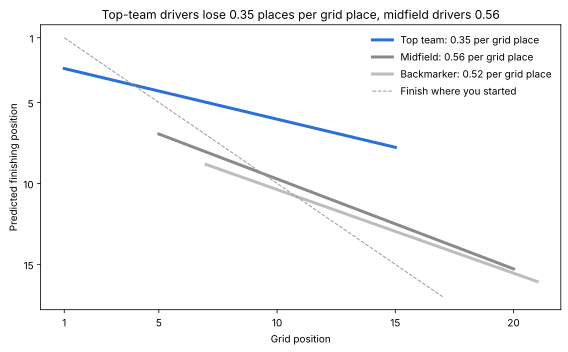

In [9]:
# interaction plot: predicted finishing position by grid position, permanent circuits
b = m3.params
fig, ax = plt.subplots(figsize=(8, 5))
for tier, name, colour in [(1, "Top team", "#2a6fdb"), (2, "Midfield", "#8a8a8a"), (3, "Backmarker", "#bdbdbd")]:
    g = fin[fin.tier == tier].grid
    lo, hi = int(g.quantile(0.05)), int(g.quantile(0.95))
    grid = np.arange(lo, hi + 1)
    shift = 0 if tier == 1 else b[f"C(tier)[T.{tier}]"]
    slope = b["grid_c"] + (0 if tier == 1 else b[f"grid_c:C(tier)[T.{tier}]"])
    ax.plot(grid, b["Intercept"] + shift + slope * (grid - 10), color=colour, lw=3, label=f"{name}: {slope:.2f} per grid place")
ax.plot([1, 17], [1, 17], ls="--", color="#999", lw=1, label="Finish where you started")
ax.set_xticks([1, 5, 10, 15, 20])
ax.set_yticks([1, 5, 10, 15])
ax.invert_yaxis()
ax.set_xlabel("Grid position")
ax.set_ylabel("Predicted finishing position")
ax.set_title("Top-team drivers lose 0.35 places per grid place, midfield drivers 0.56")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("grid_effect_by_tier.svg")
plt.show()

## 6. Retirements and the street effect

In [10]:
rate = starters.groupby("street").classified.apply(lambda s: (~s).mean())
per_race = starters.assign(dnf=~starters.classified).groupby(["street", "race_id"]).dnf.sum().groupby("street").mean()
print(f"Not classified: street {rate[1]:.1%}, permanent {rate[0]:.1%}")
print(f"Retirements per race: street {per_race[1]:.1f}, permanent {per_race[0]:.1f}")

starters["dnf"] = (~starters.classified).astype(int)
logit = smf.logit("dnf ~ street + C(tier) + grid", starters).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(starters.race_id)[0]})
lo, hi = np.exp(logit.conf_int().loc["street"])
print(f"Odds ratio of retiring on a street circuit: {np.exp(logit.params['street']):.2f} [{lo:.2f}, {hi:.2f}], p = {logit.pvalues['street']:.3f}")

m4 = clustered("position ~ grid + C(tier) + street + ret_ahead", fin)
print(f"Each retirement ahead: {m4.params['ret_ahead']:.2f} places")
print(f"Street with retirements ahead controlled: {m4.params['street']:.2f}, p = {m4.pvalues['street']:.3f}")

m5 = clustered("position ~ grid + C(tier) + street", starters)
print(f"All starters (official results order): street {m5.params['street']:.2f}, p = {m5.pvalues['street']:.3f}, "
      f"R2 = {smf.ols('position ~ grid + C(tier) + street', starters).fit().rsquared:.3f}")

mts = clustered("position ~ grid + C(tier) * street", fin)
w = mts.wald_test("C(tier)[T.2]:street = 0, C(tier)[T.3]:street = 0", scalar=True)
print(f"Tier x street (joint): chi2(2) = {w.statistic:.2f}, p = {w.pvalue:.3f}")

Not classified: street 20.9%, permanent 15.5%
Retirements per race: street 4.2, permanent 3.1
Odds ratio of retiring on a street circuit: 1.43 [1.15, 1.79], p = 0.002
Each retirement ahead: -0.89 places
Street with retirements ahead controlled: -0.05, p = 0.302
All starters (official results order): street 0.01, p = 0.724, R2 = 0.418
Tier x street (joint): chi2(2) = 1.40, p = 0.496


## 7. Prediction on unseen races

In [11]:
formulas = {"Grid position only": "position ~ grid",
            "Grid, tier and street": "position ~ grid + C(tier) + street",
            "With interactions": "position ~ grid_c * street + grid_c * C(tier)"}

def score(train, test, f):
    pred = smf.ols(f, train).fit().predict(test)
    mae = (test.position - pred).abs().mean()
    r2 = 1 - ((test.position - pred) ** 2).sum() / ((test.position - test.position.mean()) ** 2).sum()
    return mae, r2

def cv_by_race(f, data, k=5):
    out = [score(data.iloc[a], data.iloc[b], f) for a, b in GroupKFold(n_splits=k).split(data, groups=data.race_id)]
    return np.mean([o[0] for o in out]), np.mean([o[1] for o in out])

train, test = fin[fin.season <= 2019], fin[fin.season >= 2020]
table = []
for name, f in formulas.items():
    table.append((name, *cv_by_race(f, fin), *score(train, test, f)))
print(f"Training-average baseline, 2020-21 MAE: {(test.position - train.position.mean()).abs().mean():.2f}")

Training-average baseline, 2020-21 MAE: 4.41


## 8. Robustness

In [12]:
# tiers from the previous season's constructors' championship: 1st-3rd top, 4th-7th midfield, 8th or lower backmarker
PREDECESSOR = {"renault": "lotus_f1", "racing_point": "force_india", "aston_martin": "racing_point",
               "alphatauri": "toro_rosso", "alfa": "sauber", "alpine": "renault", "manor": "marussia"}
rank = {}
for y in range(2013, 2022):
    st = json.load(open(f"{DATA}/constructor_standings_{y}.json"))["MRData"]["StandingsTable"]["StandingsLists"][0]
    for s in st["ConstructorStandings"]:
        rank[(y, s["Constructor"]["constructorId"])] = int(s["position"])

def previous_rank(season, cid):
    for c in (cid, PREDECESSOR.get(cid)):
        if (season - 1, c) in rank:
            return rank[(season - 1, c)]
    return None   # Haas in 2016: no previous season

fin["lag_rank"] = [previous_rank(s, c) for s, c in zip(fin.season, fin.constructor_id)]
fin["tier_lag"] = [3 if r is None else (1 if r <= 3 else 2 if r <= 7 else 3) for r in fin.lag_rank]
print(f"Entries keeping their original tier: {(fin.tier_lag == fin.tier).mean():.0%}")

ml3 = clustered("position ~ grid_c * street + grid_c * C(tier_lag)", fin)
wl = ml3.wald_test("grid_c:C(tier_lag)[T.2] = 0, grid_c:C(tier_lag)[T.3] = 0", scalar=True)
print(f"Grid x tier: chi2(2) = {wl.statistic:.1f}, p = {wl.pvalue:.2g}; grid x street p = {ml3.pvalues['grid_c:street']:.3f}")
ml4 = clustered("position ~ grid + C(tier_lag) + street + ret_ahead", fin)
print(f"Street with retirements ahead: {ml4.params['street']:.2f}, p = {ml4.pvalues['street']:.3f}")

f_lag = "position ~ grid + C(tier_lag) + street"
train, test = fin[fin.season <= 2019], fin[fin.season >= 2020]   # re-split so both halves carry tier_lag
table.append(("Grid, street and previous-season tier", *cv_by_race(f_lag, fin), *score(train, test, f_lag)))
pd.DataFrame(table, columns=["Model", "CV MAE", "CV R2", "2020-21 MAE", "2020-21 R2"]).round(3)

Entries keeping their original tier: 64%
Grid x tier: chi2(2) = 15.5, p = 0.00043; grid x street p = 0.340
Street with retirements ahead: -0.04, p = 0.279


,Model,CV MAE,CV R2,2020-21 MAE,2020-21 R2
0,Grid position only,2.571,0.568,2.692,0.547
1,"Grid, tier and street",2.404,0.621,2.702,0.550
2,With interactions,2.402,0.626,2.688,0.553
3,"Grid, street and previous-season tier",2.406,0.617,2.563,0.585


In [13]:
# finishing position is a rank: check the main-effects model as an ordered logit
X = fin[["grid", "street"]].assign(midfield=(fin.tier == 2).astype(float), backmarker=(fin.tier == 3).astype(float)).astype(float)
ol = OrderedModel(fin.position.astype(int), X, distr="logit").fit(method="bfgs", disp=0, maxiter=2000)
pd.DataFrame({"coef": ol.params[["grid", "street", "midfield", "backmarker"]],
              "p": ol.pvalues[["grid", "street", "midfield", "backmarker"]]}).round(3)

,coef,p
grid,0.289,0.000
street,-0.182,0.022
midfield,1.992,0.000
backmarker,2.302,0.000
